In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt

!pip install pytabkit
import torch
import pytabkit
from pytabkit import RealMLP_TD_Classifier

warnings.filterwarnings('ignore')
print("PyTorch  version:", torch.__version__)


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 364.0/364.0 kB 13.8 MB/s eta 0:00:00
PyTorch  version: 2.11.0+cu128
/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv
/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/data.csv


In [2]:
train = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/train.csv')
test = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/test.csv')
sub = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv')
org = pd.read_csv('/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/data.csv')
print(train.shape)
print(test.shape)
print(sub.shape)
print(org.shape)

(699635, 23)
(299844, 22)
(299844, 2)
(129880, 22)


In [3]:
org['id'] = 0
org.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction', 'id'],
      dtype='object')

In [4]:
org = org[train.columns]


In [5]:
train = pd.concat([train,org]).reset_index(drop = True)
print(train.shape)

(829515, 23)


In [6]:
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [7]:
train.tail()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
829510,0,34,526,3,3,3,1,4,3,4,4,3,2,4,4,4,0,0.0,Male,disloyal Customer,Business travel,Business,False
829511,0,23,646,4,4,4,4,4,4,4,4,4,5,5,5,4,0,0.0,Male,Loyal Customer,Business travel,Business,True
829512,0,17,828,2,5,1,5,2,1,2,2,4,3,4,5,2,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
829513,0,14,1127,3,3,3,3,4,4,4,4,3,2,5,4,4,0,0.0,Male,Loyal Customer,Business travel,Business,True
829514,0,42,264,2,5,2,5,4,2,2,1,1,2,1,1,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False


In [8]:
eda = pd.DataFrame()
eda['nlevel'] = train.nunique()
eda['nmiss'] = train.isnull().sum()
eda['dtypes'] = train.dtypes
eda

,nlevel,nmiss,dtypes
id,699635,0,int64
Age,75,0,int64
Flight Distance,3824,0,int64
Inflight wifi service,6,0,int64
Departure/Arrival time convenient,6,0,int64
Ease of Online booking,6,0,int64
Gate location,6,0,int64
Food and drink,6,0,int64
Online boarding,6,0,int64
Seat comfort,6,0,int64


In [9]:
train.duplicated().sum()

np.int64(0)

In [10]:
train.satisfaction = train.satisfaction.astype(int)
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [11]:
num_cols = train.select_dtypes(include = 'number').columns
print(num_cols)
cat_cols = train.select_dtypes(include = 'object').columns
print(cat_cols)

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')
Index(['Gender', 'Customer Type', 'Type of Travel', 'Class'], dtype='object')


In [12]:
num_cols = ['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes']

target = 'satisfaction'

cat_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

### Histogram of numerical features

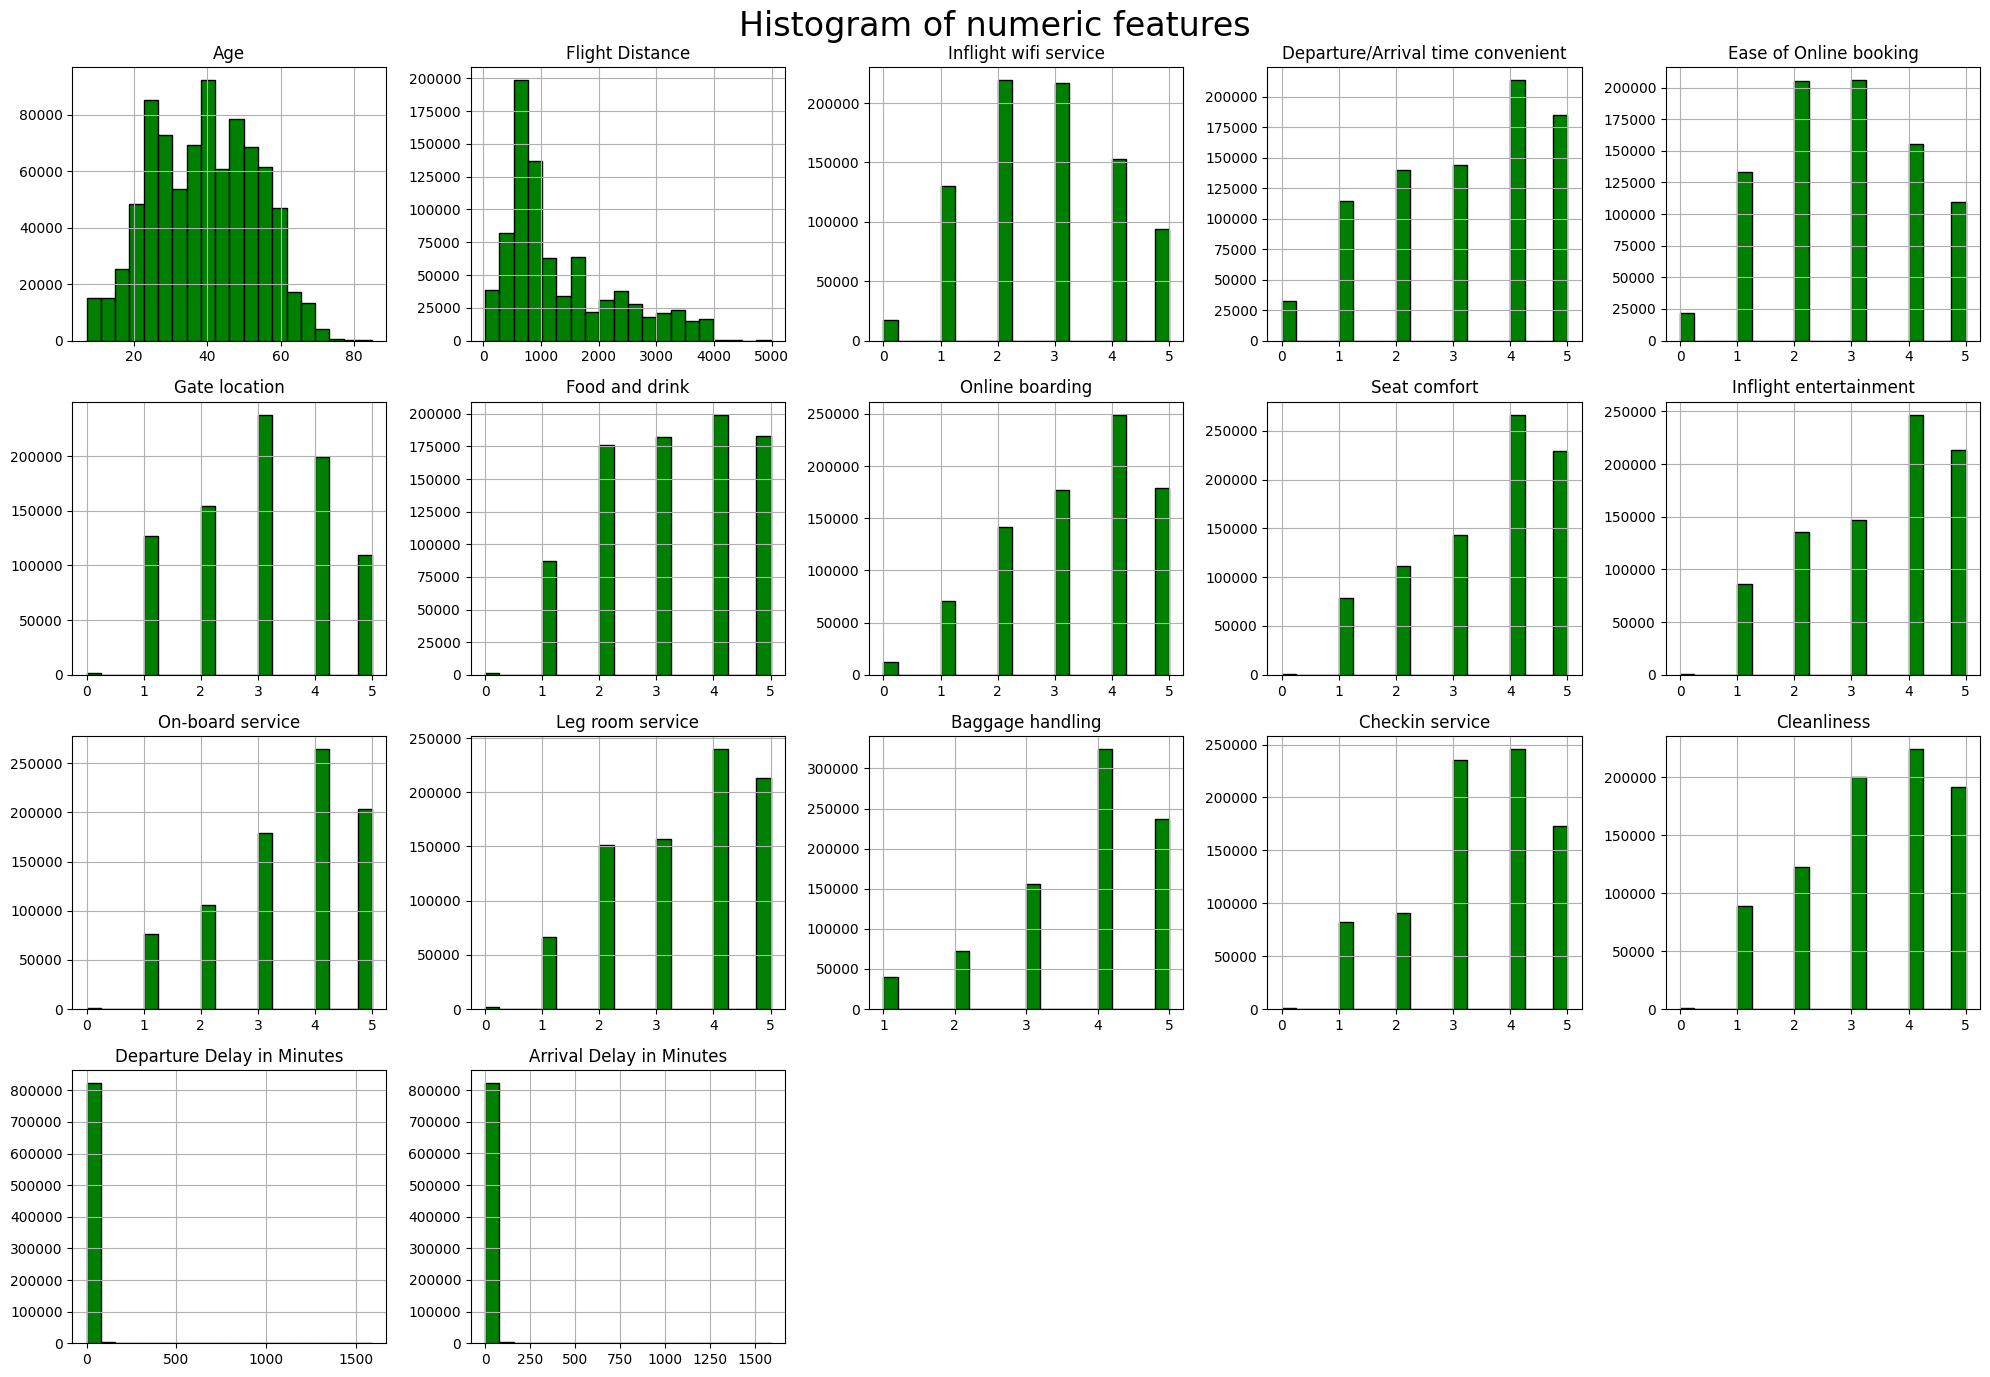

In [13]:
train[num_cols].hist(layout=(4, 5), bins=20, figsize=(20, 14), color='green', edgecolor='black')
plt.suptitle('Histogram of numeric features', fontsize = 24)
plt.tight_layout()
plt.show()

In [14]:
train[num_cols+[target]].corr()[target].reset_index().sort_values(by = target,ascending = False).head(30)

,index,satisfaction
17,satisfaction,1.000000
7,Online boarding,0.550017
9,Inflight entertainment,0.425592
8,Seat comfort,0.392961
1,Flight Distance,0.358038
10,On-board service,0.342629
14,Cleanliness,0.333795
11,Leg room service,0.327267
2,Inflight wifi service,0.290042
12,Baggage handling,0.256332


### Target mean by categorical features

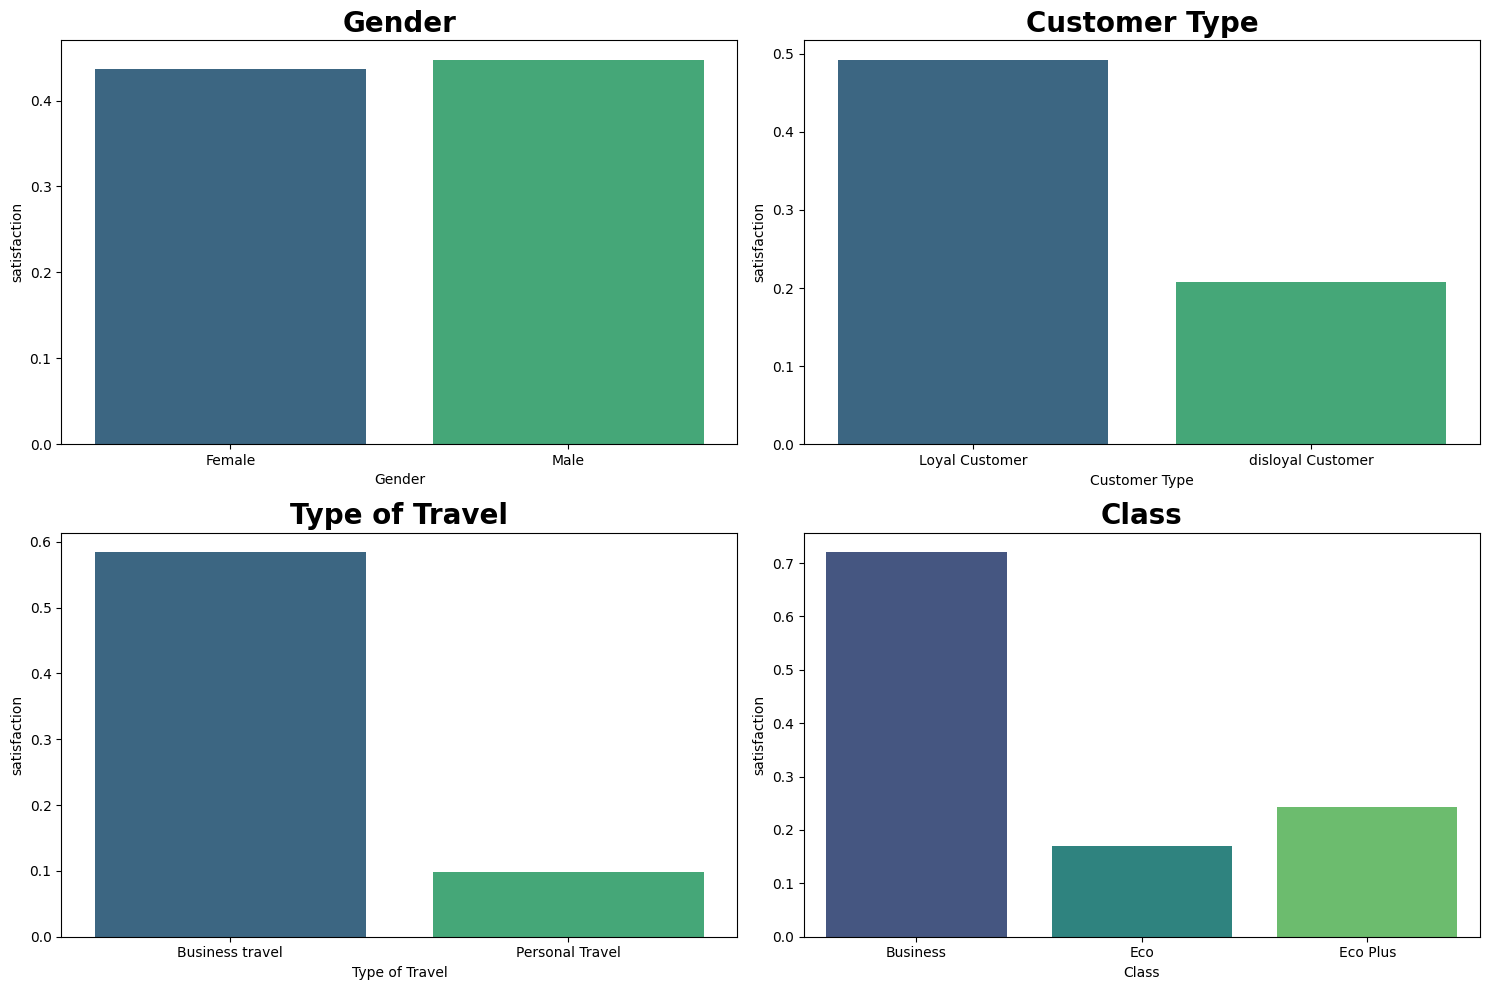

In [15]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
axes = axes.flatten()  # Flatten the 2D array of axes into a 1D array for easier looping

# 4. Loop through features and plot target mean on each subplot
for i, col in enumerate(cat_cols):
    # Calculate the mean target value for each category
    mean_data = train.groupby(col)[target].mean().reset_index()
    
    # Generate the bar plot on the specific subplot axis
    sns.barplot(
        x=col, 
        y=target, 
        data=mean_data, 
        ax=axes[i], 
        palette="viridis", 
        hue=col, 
        legend=False
    )
    
    # Formatting adjustments for readability
    axes[i].set_title(col, fontsize=20, fontweight='bold')
   

# 5. Clean layout formatting
plt.tight_layout()
plt.show()

###  Distribution of categorical features

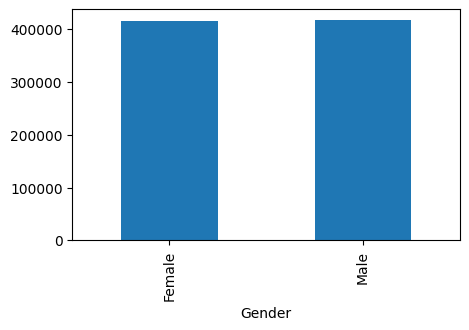

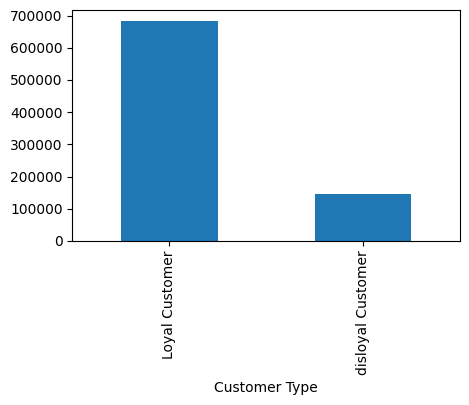

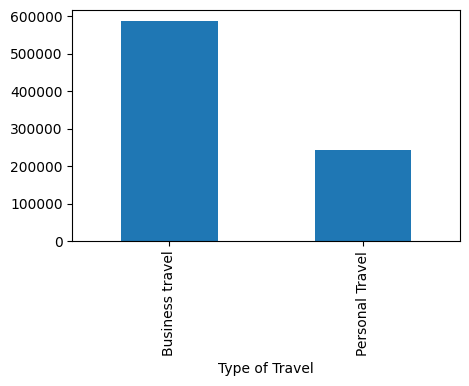

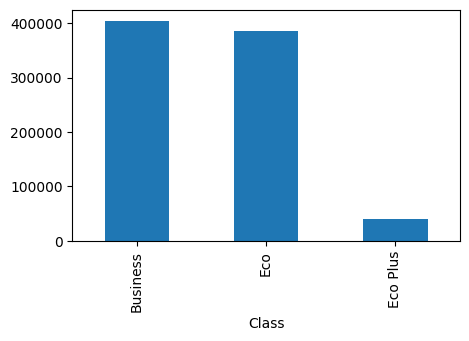

In [16]:
for c in cat_cols :
    train.groupby(c).size().plot(kind = 'bar', figsize = (5,3))
    plt.show()

<Axes: >

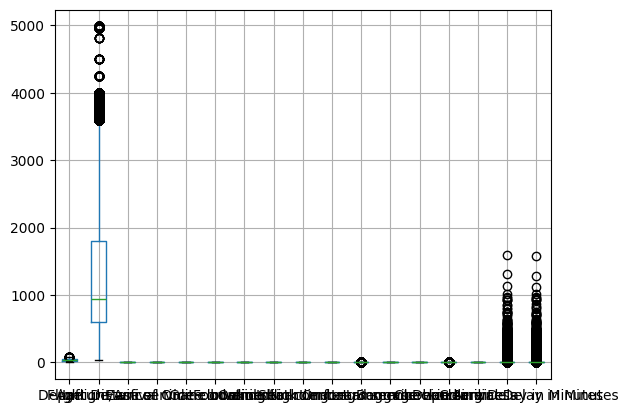

In [17]:
train[num_cols].boxplot()

In [18]:
train.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
count,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,829515.000000,828830.000000,829515.000000
mean,295044.956143,39.068633,1328.184849,2.770889,3.140770,2.804415,3.007971,3.256114,3.346694,3.548973,3.438905,3.496364,3.453749,3.778304,3.402438,3.365672,3.295822,3.314740,0.442146
std,224865.044838,14.016409,963.120079,1.288329,1.483979,1.341265,1.257953,1.305088,1.299102,1.283152,1.312706,1.247168,1.279591,1.097386,1.220177,1.283998,16.772673,16.873761,0.496642
min,0.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,77498.500000,27.000000,602.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000,0.000000
50%,284877.000000,40.000000,946.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000,0.000000
75%,492255.500000,50.000000,1797.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000,1.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000,1.000000


In [19]:
train[train['Departure Delay in Minutes']>60]['satisfaction'].value_counts()

satisfaction
0    5999
1    3329
Name: count, dtype: int64

In [20]:
len(train[train['Departure Delay in Minutes']>180])

1344

In [21]:
train[train['Arrival Delay in Minutes']>60]['satisfaction'].value_counts()

satisfaction
0    6069
1    3329
Name: count, dtype: int64

In [22]:
len(train[train['Arrival Delay in Minutes']>180])

1360

### Target distribution

In [23]:
train[target].value_counts()

satisfaction
0    462748
1    366767
Name: count, dtype: int64

# FE

In [24]:
train.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='object')

In [25]:

df = pd.concat([train,test]).reset_index(drop = True)
print(df.shape)

(1129359, 23)


In [26]:
# ######################### Agg features   
main_cols = num_cols + ['Delay_Mins', 'Delay/Dist']
ag_cols = cat_cols



df['customer_travel'] = df['Customer Type'] + '_' + df['Type of Travel']
df['class_travel'] = df['Class'] + '_' + df['Type of Travel']
df['class_customer'] = df['Customer Type'] + '_' + df['Class']

df['Arrival Delay in Minutes > 180'] = (df['Arrival Delay in Minutes'] > 180).astype(int)
df['Arrival Delay in Minutes > 60'] = (df['Arrival Delay in Minutes'] > 60).astype(int)
df['Departure Delay in Minutes > 180'] = (df['Departure Delay in Minutes'] > 180).astype(int)
df['Departure Delay in Minutes > 60'] = (df['Departure Delay in Minutes'] > 60).astype(int)

df['Delay_Mins'] = df['Departure Delay in Minutes'] + df['Arrival Delay in Minutes']

df['Delay_Mins > 60'] = (df['Delay_Mins'] > 60).astype(int)
df['Delay_Mins > 120'] = (df['Delay_Mins'] > 120).astype(int)
df['Delay_Mins > 180'] = (df['Delay_Mins'] > 180).astype(int)

df['Delay/Dist'] = df['Delay_Mins']/df['Flight Distance']

# List of columns
fe_cols = [ 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness']

# Iterate through every 2 columns and create a new sum column
for i in range(0, len(fe_cols)-1, 2):
  col1 = fe_cols[i]
  col2 = fe_cols[i + 1]
  new_col_name = f"avg_{col1}_{col2}"
  df[new_col_name] = df[[col1, col2]].mean(axis=1)


for col in ag_cols:    
    fq_encode = df[col].value_counts(dropna= True, normalize = True).to_dict()   
    df[col+'_fq_enc'] = df[col].map(fq_encode)
    
for col_a in main_cols: 
    for col_b in ag_cols:
        df[col_a + '_' + col_b + '_mean'] = df.groupby(col_b)[col_a].transform('mean')    
        df[col_a + '_' + col_b + '_std'] = df.groupby(col_b)[col_a].transform('std')
        #df[col_a + '_' + col_b + '_median'] = df.groupby(col_b)[col_a].transform('median')


print(df.shape)
df.head()

(1129359, 197)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,customer_travel,class_travel,class_customer,Arrival Delay in Minutes > 180,Arrival Delay in Minutes > 60,Departure Delay in Minutes > 180,Departure Delay in Minutes > 60,Delay_Mins,Delay_Mins > 60,Delay_Mins > 120,Delay_Mins > 180,Delay/Dist,avg_Inflight wifi service_Departure/Arrival time convenient,avg_Ease of Online booking_Gate location,avg_Food and drink_Online boarding,avg_Seat comfort_Inflight entertainment,avg_On-board service_Leg room service,avg_Baggage handling_Checkin service,Gender_fq_enc,Customer Type_fq_enc,Type of Travel_fq_enc,Class_fq_enc,Age_Gender_mean,Age_Gender_std,Age_Customer Type_mean,Age_Customer Type_std,Age_Type of Travel_mean,Age_Type of Travel_std,Age_Class_mean,Age_Class_std,Flight Distance_Gender_mean,Flight Distance_Gender_std,Flight Distance_Customer Type_mean,Flight Distance_Customer Type_std,Flight Distance_Type of Travel_mean,Flight Distance_Type of Travel_std,Flight Distance_Class_mean,Flight Distance_Class_std,Inflight wifi service_Gender_mean,Inflight wifi service_Gender_std,Inflight wifi service_Customer Type_mean,Inflight wifi service_Customer Type_std,Inflight wifi service_Type of Travel_mean,Inflight wifi service_Type of Travel_std,Inflight wifi service_Class_mean,Inflight wifi service_Class_std,Departure/Arrival time convenient_Gender_mean,Departure/Arrival time convenient_Gender_std,Departure/Arrival time convenient_Customer Type_mean,Departure/Arrival time convenient_Customer Type_std,Departure/Arrival time convenient_Type of Travel_mean,Departure/Arrival time convenient_Type of Travel_std,Departure/Arrival time convenient_Class_mean,Departure/Arrival time convenient_Class_std,Ease of Online booking_Gender_mean,Ease of Online booking_Gender_std,Ease of Online booking_Customer Type_mean,Ease of Online booking_Customer Type_std,Ease of Online booking_Type of Travel_mean,Ease of Online booking_Type of Travel_std,Ease of Online booking_Class_mean,Ease of Online booking_Class_std,Gate location_Gender_mean,Gate location_Gender_std,Gate location_Customer Type_mean,Gate location_Customer Type_std,Gate location_Type of Travel_mean,Gate location_Type of Travel_std,Gate location_Class_mean,Gate location_Class_std,Food and drink_Gender_mean,Food and drink_Gender_std,Food and drink_Customer Type_mean,Food and drink_Customer Type_std,Food and drink_Type of Travel_mean,Food and drink_Type of Travel_std,Food and drink_Class_mean,Food and drink_Class_std,Online boarding_Gender_mean,Online boarding_Gender_std,Online boarding_Customer Type_mean,Online boarding_Customer Type_std,Online boarding_Type of Travel_mean,Online boarding_Type of Travel_std,Online boarding_Class_mean,Online boarding_Class_std,Seat comfort_Gender_mean,Seat comfort_Gender_std,Seat comfort_Customer Type_mean,Seat comfort_Customer Type_std,Seat comfort_Type of Travel_mean,Seat comfort_Type of Travel_std,Seat comfort_Class_mean,Seat comfort_Class_std,Inflight entertainment_Gender_mean,Inflight entertainment_Gender_std,Inflight entertainment_Customer Type_mean,Inflight entertainment_Customer Type_std,Inflight entertainment_Type of Travel_mean,Inflight entertainment_Type of Travel_std,Inflight entertainment_Class_mean,Inflight entertainment_Class_std,On-board service_Gender_mean,On-board service_Gender_std,On-board service_Customer Type_mean,On-board service_Customer Type_std,On-board service_Type of Travel_mean,On-board service_Type of Travel_std,On-board service_Class_mean,On-board service_Class_std,Leg room service_Gender_mean,Leg room service_Gender_std,Leg room service_Customer Type_mean,Leg room service_Customer Type_std,Leg room service_Type of Travel_mean,Leg ro

In [27]:
cat_cols

['Gender', 'Customer Type', 'Type of Travel', 'Class']

In [28]:
digit_num_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes',
 'Arrival Delay in Minutes']
for col in digit_num_cols:
    for k in range(-2, 4):
        new_col = f'{col}_digit{k}'
        df[new_col] = (df[col].fillna(0) // (10**k) % 10).astype('int8')

print(f"digit features: {len(digit_num_cols) * 8}")
print(f"df shape: {df.shape} | df shape: {df.shape}")

digit features: 32
df shape: (1129359, 221) | df shape: (1129359, 221)


# Preprocessing

In [29]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()


for c in cat_cols +['customer_travel','class_travel','class_customer']:
    df[c] = le.fit_transform(df[c])

df.head(3)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,customer_travel,class_travel,class_customer,Arrival Delay in Minutes > 180,Arrival Delay in Minutes > 60,Departure Delay in Minutes > 180,Departure Delay in Minutes > 60,Delay_Mins,Delay_Mins > 60,Delay_Mins > 120,Delay_Mins > 180,Delay/Dist,avg_Inflight wifi service_Departure/Arrival time convenient,avg_Ease of Online booking_Gate location,avg_Food and drink_Online boarding,avg_Seat comfort_Inflight entertainment,avg_On-board service_Leg room service,avg_Baggage handling_Checkin service,Gender_fq_enc,Customer Type_fq_enc,Type of Travel_fq_enc,Class_fq_enc,Age_Gender_mean,Age_Gender_std,Age_Customer Type_mean,Age_Customer Type_std,Age_Type of Travel_mean,Age_Type of Travel_std,Age_Class_mean,Age_Class_std,Flight Distance_Gender_mean,Flight Distance_Gender_std,Flight Distance_Customer Type_mean,Flight Distance_Customer Type_std,Flight Distance_Type of Travel_mean,Flight Distance_Type of Travel_std,Flight Distance_Class_mean,Flight Distance_Class_std,Inflight wifi service_Gender_mean,Inflight wifi service_Gender_std,Inflight wifi service_Customer Type_mean,Inflight wifi service_Customer Type_std,Inflight wifi service_Type of Travel_mean,Inflight wifi service_Type of Travel_std,Inflight wifi service_Class_mean,Inflight wifi service_Class_std,Departure/Arrival time convenient_Gender_mean,Departure/Arrival time convenient_Gender_std,Departure/Arrival time convenient_Customer Type_mean,Departure/Arrival time convenient_Customer Type_std,Departure/Arrival time convenient_Type of Travel_mean,Departure/Arrival time convenient_Type of Travel_std,Departure/Arrival time convenient_Class_mean,Departure/Arrival time convenient_Class_std,Ease of Online booking_Gender_mean,Ease of Online booking_Gender_std,Ease of Online booking_Customer Type_mean,Ease of Online booking_Customer Type_std,Ease of Online booking_Type of Travel_mean,Ease of Online booking_Type of Travel_std,Ease of Online booking_Class_mean,Ease of Online booking_Class_std,Gate location_Gender_mean,Gate location_Gender_std,Gate location_Customer Type_mean,Gate location_Customer Type_std,Gate location_Type of Travel_mean,Gate location_Type of Travel_std,Gate location_Class_mean,Gate location_Class_std,Food and drink_Gender_mean,Food and drink_Gender_std,Food and drink_Customer Type_mean,Food and drink_Customer Type_std,Food and drink_Type of Travel_mean,Food and drink_Type of Travel_std,Food and drink_Class_mean,Food and drink_Class_std,Online boarding_Gender_mean,Online boarding_Gender_std,Online boarding_Customer Type_mean,Online boarding_Customer Type_std,Online boarding_Type of Travel_mean,Online boarding_Type of Travel_std,Online boarding_Class_mean,Online boarding_Class_std,Seat comfort_Gender_mean,Seat comfort_Gender_std,Seat comfort_Customer Type_mean,Seat comfort_Customer Type_std,Seat comfort_Type of Travel_mean,Seat comfort_Type of Travel_std,Seat comfort_Class_mean,Seat comfort_Class_std,Inflight entertainment_Gender_mean,Inflight entertainment_Gender_std,Inflight entertainment_Customer Type_mean,Inflight entertainment_Customer Type_std,Inflight entertainment_Type of Travel_mean,Inflight entertainment_Type of Travel_std,Inflight entertainment_Class_mean,Inflight entertainment_Class_std,On-board service_Gender_mean,On-board service_Gender_std,On-board service_Customer Type_mean,On-board service_Customer Type_std,On-board service_Type of Travel_mean,On-board service_Type of Travel_std,On-board service_Class_mean,On-board service_Class_std,Leg room service_Gender_mean,Leg room service_Gender_std,Leg room service_Customer Type_mean,Leg room service_Customer Type_std,Leg room service_Type of Travel_mean,Leg ro

In [30]:
df.isnull().sum().sort_values(ascending = False).head(30)

satisfaction                         299844
Arrival Delay in Minutes                815
Delay_Mins                              815
Delay/Dist                              815
Flight Distance                           0
Ease of Online booking                    0
Gate location                             0
Food and drink                            0
Online boarding                           0
Seat comfort                              0
Inflight entertainment                    0
Age                                       0
id                                        0
Leg room service                          0
On-board service                          0
Cleanliness                               0
Baggage handling                          0
Departure Delay in Minutes                0
Gender                                    0
Customer Type                             0
Checkin service                           0
Type of Travel                            0
Class                           

In [31]:
target

'satisfaction'

In [32]:
df = df.fillna(-1)

# Model Development

In [33]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold



train = df[:len(train)]
test = df[-len(test):]
print(train.shape)
print(test.shape)


X_train = train.drop(['id','satisfaction'], axis = 1)
X_test = test.drop(['id','satisfaction'], axis = 1)

y_train = train[target]
print(X_train.shape)
print(X_test.shape)

#train.corr(numeric_only = True)[target].reset_index().sort_values(by = target,ascending = False).head(30)

(829515, 221)
(299844, 221)
(829515, 219)
(299844, 219)


In [34]:
X_train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,customer_travel,class_travel,class_customer,Arrival Delay in Minutes > 180,Arrival Delay in Minutes > 60,Departure Delay in Minutes > 180,Departure Delay in Minutes > 60,Delay_Mins,Delay_Mins > 60,Delay_Mins > 120,Delay_Mins > 180,Delay/Dist,avg_Inflight wifi service_Departure/Arrival time convenient,avg_Ease of Online booking_Gate location,avg_Food and drink_Online boarding,avg_Seat comfort_Inflight entertainment,avg_On-board service_Leg room service,avg_Baggage handling_Checkin service,Gender_fq_enc,Customer Type_fq_enc,Type of Travel_fq_enc,Class_fq_enc,Age_Gender_mean,Age_Gender_std,Age_Customer Type_mean,Age_Customer Type_std,Age_Type of Travel_mean,Age_Type of Travel_std,Age_Class_mean,Age_Class_std,Flight Distance_Gender_mean,Flight Distance_Gender_std,Flight Distance_Customer Type_mean,Flight Distance_Customer Type_std,Flight Distance_Type of Travel_mean,Flight Distance_Type of Travel_std,Flight Distance_Class_mean,Flight Distance_Class_std,Inflight wifi service_Gender_mean,Inflight wifi service_Gender_std,Inflight wifi service_Customer Type_mean,Inflight wifi service_Customer Type_std,Inflight wifi service_Type of Travel_mean,Inflight wifi service_Type of Travel_std,Inflight wifi service_Class_mean,Inflight wifi service_Class_std,Departure/Arrival time convenient_Gender_mean,Departure/Arrival time convenient_Gender_std,Departure/Arrival time convenient_Customer Type_mean,Departure/Arrival time convenient_Customer Type_std,Departure/Arrival time convenient_Type of Travel_mean,Departure/Arrival time convenient_Type of Travel_std,Departure/Arrival time convenient_Class_mean,Departure/Arrival time convenient_Class_std,Ease of Online booking_Gender_mean,Ease of Online booking_Gender_std,Ease of Online booking_Customer Type_mean,Ease of Online booking_Customer Type_std,Ease of Online booking_Type of Travel_mean,Ease of Online booking_Type of Travel_std,Ease of Online booking_Class_mean,Ease of Online booking_Class_std,Gate location_Gender_mean,Gate location_Gender_std,Gate location_Customer Type_mean,Gate location_Customer Type_std,Gate location_Type of Travel_mean,Gate location_Type of Travel_std,Gate location_Class_mean,Gate location_Class_std,Food and drink_Gender_mean,Food and drink_Gender_std,Food and drink_Customer Type_mean,Food and drink_Customer Type_std,Food and drink_Type of Travel_mean,Food and drink_Type of Travel_std,Food and drink_Class_mean,Food and drink_Class_std,Online boarding_Gender_mean,Online boarding_Gender_std,Online boarding_Customer Type_mean,Online boarding_Customer Type_std,Online boarding_Type of Travel_mean,Online boarding_Type of Travel_std,Online boarding_Class_mean,Online boarding_Class_std,Seat comfort_Gender_mean,Seat comfort_Gender_std,Seat comfort_Customer Type_mean,Seat comfort_Customer Type_std,Seat comfort_Type of Travel_mean,Seat comfort_Type of Travel_std,Seat comfort_Class_mean,Seat comfort_Class_std,Inflight entertainment_Gender_mean,Inflight entertainment_Gender_std,Inflight entertainment_Customer Type_mean,Inflight entertainment_Customer Type_std,Inflight entertainment_Type of Travel_mean,Inflight entertainment_Type of Travel_std,Inflight entertainment_Class_mean,Inflight entertainment_Class_std,On-board service_Gender_mean,On-board service_Gender_std,On-board service_Customer Type_mean,On-board service_Customer Type_std,On-board service_Type of Travel_mean,On-board service_Type of Travel_std,On-board service_Class_mean,On-board service_Class_std,Leg room service_Gender_mean,Leg room service_Gender_std,Leg room service_Customer Type_mean,Leg room service_Customer Type_std,Leg room service_Type of Travel_mean,Leg room service_Type 

In [35]:
params = {
    'random_state': 42,
    'verbosity': 2,
    'val_metric_name': '1-auc_ovr',

    'n_ens': 8,
    'n_epochs': 3,
    'batch_size': 288,
    'use_early_stopping': False,
    'early_stopping_additive_patience': 10,
    'early_stopping_multiplicative_patience': 1,

    'lr': 0.053,
    'wd': 0.015,
    'sq_mom': 0.988,
    'lr_sched': 'flat_anneal',
    'wd_sched': 'cos_log_15',
    'first_layer_lr_factor': 0.25,

    'embedding_size': 5,
    'max_one_hot_cat_size': 2,
    'hidden_sizes': [512, 256, 128],
    'act': 'silu',
    'p_drop': 0.05,
    'p_drop_sched': 'pow5',

    'plr_hidden_1': 16,
    'plr_hidden_2': 8,
    'plr_act_name': 'gelu',
    'plr_lr_factor': 0.1151,
    'plr_sigma': 0.75,

    'ls_eps': 0.01,
    'ls_eps_sched': 'sqrt_cos',

    'add_front_scale': False,
    'bias_init_mode': 'neg-uniform-dynamic-2',
    'tfms': ['one_hot', 'median_center', 'robust_scale',
             'smooth_clip', 'embedding', 'l2_normalize'],
}

In [36]:
%%time
from sklearn.preprocessing import TargetEncoder

kf = KFold(n_splits = 5, shuffle = True, random_state = 2025)

Folds = 5

preds_nn = np.zeros(len(sub))
oof_nn = np.zeros(len(X_train))

TARGET_ENCODE_COLS = cat_cols

#LGBM
for i, (idxt, idxv) in enumerate(kf.split(X_train, y_train)):

    print('Fold:', i+1)
    print('*'* 50)

    X_trn, X_val = X_train.iloc[idxt], X_train.iloc[idxv]
    y_trn, y_val = y_train.iloc[idxt], y_train.iloc[idxv]
    X_test_fold = X_test.copy()


    #     # Triple Sklearn Target Encoders (Auto, Strict 10, and Massive 100)
    # te_auto = TargetEncoder(shuffle=True, cv=Folds, smooth='auto', random_state=42)
    # te_10   = TargetEncoder(shuffle=True, cv=Folds, smooth=10.0, random_state=42)
    # te_100  = TargetEncoder(shuffle=True, cv=Folds, smooth=100.0, random_state=42)
    
    # X_train_enc_auto = te_auto.fit_transform(X_trn[TARGET_ENCODE_COLS], y_trn)
    # X_valid_enc_auto = te_auto.transform(X_val[TARGET_ENCODE_COLS])
    # X_test_enc_auto  = te_auto.transform(X_test_fold[TARGET_ENCODE_COLS])

    # X_train_enc_10 = te_10.fit_transform(X_trn[TARGET_ENCODE_COLS], y_trn)
    # X_valid_enc_10 = te_10.transform(X_val[TARGET_ENCODE_COLS])
    # X_test_enc_10  = te_10.transform(X_test_fold[TARGET_ENCODE_COLS])

    # X_train_enc_100 = te_100.fit_transform(X_trn[TARGET_ENCODE_COLS], y_trn)
    # X_valid_enc_100 = te_100.transform(X_val[TARGET_ENCODE_COLS])
    # X_test_enc_100  = te_100.transform(X_test_fold[TARGET_ENCODE_COLS])
    
    # for i, col in enumerate(TARGET_ENCODE_COLS):
    #     # Auto smoothing TE
    #     X_trn[f"{col}_TE_auto"] = X_train_enc_auto[:, i].astype('float32')
    #     X_val[f"{col}_TE_auto"] = X_valid_enc_auto[:, i].astype('float32')
    #     X_test_fold[f"{col}_TE_auto"] = X_test_enc_auto[:, i].astype('float32')
        
    #     # Strict (10.0) smoothing TE
    #     X_trn[f"{col}_TE_10"] = X_train_enc_10[:, i].astype('float32')
    #     X_val[f"{col}_TE_10"] = X_valid_enc_10[:, i].astype('float32')
    #     X_test_fold[f"{col}_TE_10"] = X_test_enc_10[:, i].astype('float32')

    #     # Massive (100.0) smoothing TE (Markus's method)
    #     X_trn[f"{col}_TE_100"] = X_train_enc_100[:, i].astype('float32')
    #     X_val[f"{col}_TE_100"] = X_valid_enc_100[:, i].astype('float32')
    #     X_test_fold[f"{col}_TE_100"] = X_test_enc_100[:, i].astype('float32')
        
    #     # Drop the original string column
    #     X_trn.drop(columns=[col], inplace=True)
    #     X_val.drop(columns=[col], inplace=True)
    #     X_test_fold.drop(columns=[col], inplace=True)
    

    clf = RealMLP_TD_Classifier(**params)

    clf.fit(X_trn, y_trn, X_val, y_val)
    
    oof_nn[idxv] = clf.predict_proba(X_val)[:,1]
    preds_nn += clf.predict_proba(X_test_fold)[:,1]/kf.n_splits

print('OOF ROC', roc_auc_score(y_train, oof_nn))

Fold: 1
**************************************************
Columns classified as continuous: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'customer_travel', 'class_travel', 'class_customer', 'Arrival Delay in Minutes > 180', 'Arrival Delay in Minutes > 60', 'Departure Delay in Minutes > 180', 'Departure Delay in Minutes > 60', 'Delay_Mins', 'Delay_Mins > 60', 'Delay_Mins > 120', 'Delay_Mins > 180', 'Delay/Dist', 'avg_Inflight wifi service_Departure/Arrival time convenient', 'avg_Ease of Online booking_Gate location', 'avg_Food and drink_Online boarding', 'avg_Seat comfort_Inflight entertainment', 'avg_On-board service_Le

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Epoch 1/3: val 1-auc_ovr = 0.035391
Epoch 2/3: val 1-auc_ovr = 0.034881
Epoch 3/3: val 1-auc_ovr = 0.034331


`Trainer.fit` stopped: `max_epochs=3` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Fold: 2
**************************************************
Columns classified as continuous: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'customer_travel', 'class_travel', 'class_customer', 'Arrival Delay in Minutes > 180', 'Arrival Delay in Minutes > 60', 'Departure Delay in Minutes > 180', 'Departure Delay in Minutes > 60', 'Delay_Mins', 'Delay_Mins > 60', 'Delay_Mins > 120', 'Delay_Mins > 180', 'Delay/Dist', 'avg_Inflight wifi service_Departure/Arrival time convenient', 'avg_Ease of Online booking_Gate location', 'avg_Food and drink_Online boarding', 'avg_Seat comfort_Inflight entertainment', 'avg_On-board service_Le

...

Fold: 5
**************************************************
Columns classified as continuous: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'customer_travel', 'class_travel', 'class_customer', 'Arrival Delay in Minutes > 180', 'Arrival Delay in Minutes > 60', 'Departure Delay in Minutes > 180', 'Departure Delay in Minutes > 60', 'Delay_Mins', 'Delay_Mins > 60', 'Delay_Mins > 120', 'Delay_Mins > 180', 'Delay/Dist', 'avg_Inflight wifi service_Departure/Arrival time convenient', 'avg_Ease of Online booking_Gate location', 'avg_Food and drink_Online boarding', 'avg_Seat comfort_Inflight entertainment', 'avg_On-board service_Le

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Epoch 1/3: val 1-auc_ovr = 0.036437
Epoch 2/3: val 1-auc_ovr = 0.035831
Epoch 3/3: val 1-auc_ovr = 0.034992


`Trainer.fit` stopped: `max_epochs=3` reached.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


OOF ROC 0.9649331769682409
CPU times: user 8min 24s, sys: 2min 47s, total: 11min 12s
Wall time: 10min 37s


In [37]:
sub[target] = preds_nn
sub.to_csv('nn_submission.csv', index = False)

In [38]:
sub.head()

,id,satisfaction
0,699635,0.293181
1,699636,0.725201
2,699637,0.923770
3,699638,0.059239
4,699639,0.039819


<Axes: >

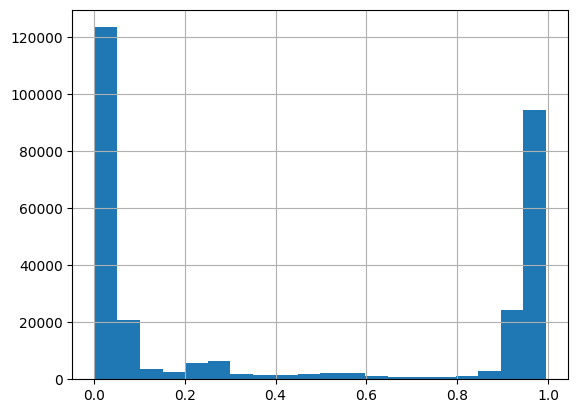

In [39]:
sub[target].hist(bins = 20)